# РГР №2. Сингулярное разложение и сжатие изображений
## Численные методы алгебры
## Ковалева Ксения и Чугуевский Роман


# Цель 

Исследовать методы вычисления сингулярного разложения матриц на примере обра-
ботки изображений, сравнить эффективность степенного метода и метода вращений
Якоби, изучить применение усеченного SVD для сжатия данных

# Теория


###  Описание сингулярного разложения (SVD)
Сингулярное разложение (Singular Value Decomposition, SVD) — это метод декомпозиции матрицы, который позволяет представить любую вещественную матрицу $A$ размера $n \times m$ в виде произведения трех матриц:
$$A = U \Sigma V^T$$
где:
* $U$ - ортогональная матрица размера $n \times n$. Ее столбцы называются левыми сингулярными векторами.
* $V$ - ортогональная матрица размера $m \times m$. Ее столбцы (строки матрицы $V^T$) называются правыми сингулярными векторами.
* $\Sigma$ - диагональная матрица размера $n \times m$, на главной диагонали которой располагаются сингулярные числа $\sigma_i$. 

Сингулярные числа $\sigma_i$ всегда неотрицательны и традиционно располагаются в порядке убывания: $\sigma_1 \geq \sigma_2 \geq \dots \geq \sigma_r > 0$, где $r$ - ранг матрицы $A$. Геометрический смысл SVD заключается в том, что любое линейное преобразование можно разложить на поворот (или отражение), масштабирование по осям и еще один поворот.

### Описание степенного метода
Степенной метод - это итерационный алгоритм, предназначенный для поиска наибольшего по модулю собственного значения и соответствующего ему собственного вектора квадратной матрицы. В контексте SVD метод применяется к матрицам $A^T A$ или $A A^T$, чтобы найти старшие сингулярные числа.

Алгоритм заключается в последовательном умножении матрицы на случайно заданный начальный вектор $v_0$ с последующей его нормализацией:
$$v_{k+1} = \frac{M v_k}{\|M v_k\|}$$
где $M = A^T A$. 

По мере увеличения числа итераций $k$, вектор $v_k$ сходится к собственному вектору, соответствующему максимальному собственному значению $\lambda_1$. Сингулярное число затем вычисляется как $\sigma_1 = \sqrt{\lambda_1}$. Для нахождения последующих сингулярных чисел применяется процедура дефляции - из исходной матрицы вычитается компонента, соответствующая уже найденному старшему сингулярному числу.

### Описание метода вращений Якоби
Метод вращений Якоби - это итерационный алгоритм для начисления всех собственных значений и собственных векторов вещественной симметричной матрицы (например, $A^T A$). 

Суть метода заключается в последовательном применении ортогональных преобразований подобия (матриц вращения Гивенса) к исходной матрице. На каждом шаге выбирается наибольший по модулю внедиагональный элемент матрицы, и вычисляется такой угол вращения $\theta$, при котором этот элемент обращается в нуль:
$$M_{new} = J^T M J$$
где $J$ - матрица вращения Якоби. 

Процесс продолжается до тех пор, пока все внедиагональные элементы не станут меньше заданного порога $\varepsilon$ (tol). В результате матрица $M$ приводится к диагональному виду, где на главной диагонали стоят собственные значения, а накопленное произведение матриц вращения $J$ дает матрицу собственных векторов. Метод Якоби обладает высокой точностью, но вычислительно затратен ($O(n^3)$) для больших матриц.

### Применение SVD для обработки изображений
Любое полутоновое изображение можно представить как матрицу пикселей $A$, где каждое значение соответствует яркости. Для цветного изображения (RGB) используются три такие матрицы - по одной для каждого цветового канала.

Сингулярное разложение позволяет реализовать усеченное SVD (Low-Rank Approximation). Оставляя только $k$ наибольших сингулярных чисел и отбрасывая остальные (где $k \ll \min(n, m)$), можно получить матрицу $A_k$:
$$A_k = U_k \Sigma_k V_k^T$$
Это свойство активно применяется в обработке изображений для:
1. Сжатия данных: Вместо хранения матрицы $n \times m$ требуется хранить только $k$ столбцов матрицы $U$, $k$ строк матрицы $V^T$ и $k$ сингулярных чисел.
2. Шумоподавления: Шум на изображении, как правило, описывается младшими (наименьшими) сингулярными числами. Отбрасывая их при восстановлении изображения, мы сглаживаем высокочастотные помехи, оставляя только главные визуальные структуры.

# Ход работы 

Загрузка изображения...
Разрешение изображения: 1024x768

Тестирование степенного метода...


Итераций:  10 | Ошибка восстановления для k=50: 55.00


Итераций:  50 | Ошибка восстановления для k=50: 54.92


Итераций: 100 | Ошибка восстановления для k=50: 54.92

Вычисляем усеченное SVD для всех каналов (k=150) для сжатия...



Анализ и визуализация...


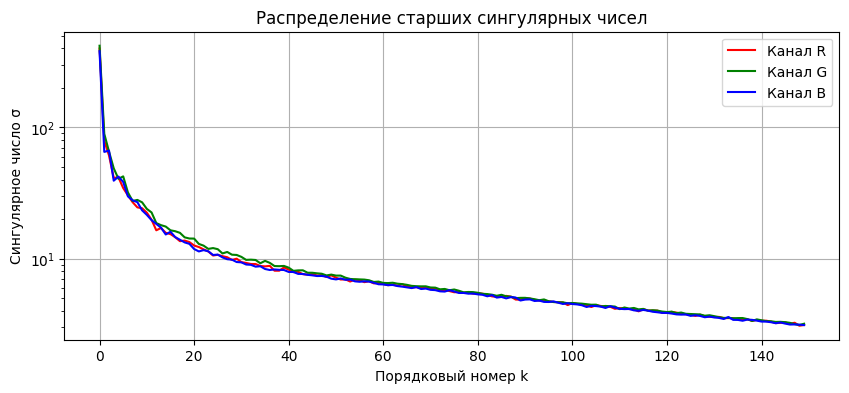

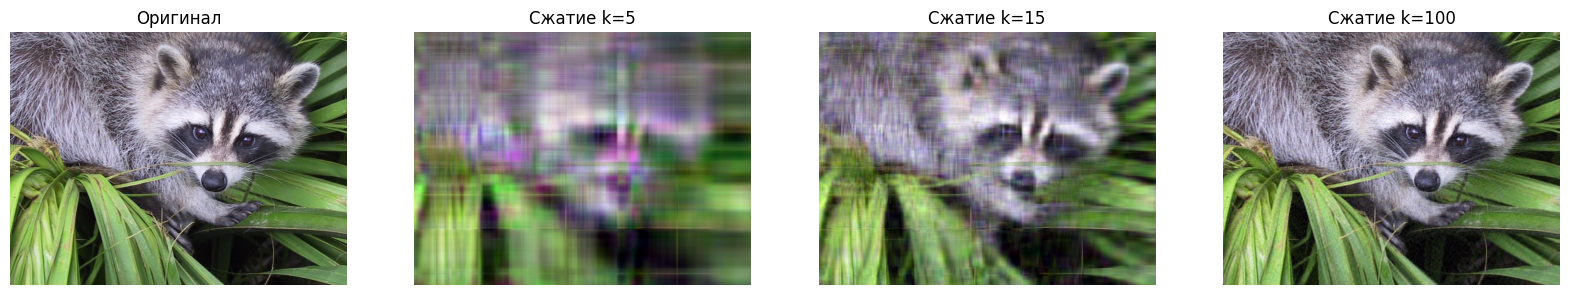


Метод вращений Якоби...
Якоби успешно завершился за 212 итераций (для блока 15x15).

Сравнение результатов (топ-5 сингулярных чисел)
Метод Якоби:     [7.17 1.39 0.92 0.44 0.24]
Степенной метод: [7.17 1.39 0.92 0.44 0.24]
Вывод по 4b: Значения старших сингулярных чисел идеально совпадают!

Сравнение порядка числа операций 
Асимптотическая сложность:
1. Степенной метод (поиск k компонент): O(k * N * n * m)
2. Метод вращений Якоби (полный спектр): O(n * m^2) + O(m^3)

Оценочное число операций для матрицы 640x640:
Степенной метод (k=50): ~ 4,096,000,000 операций
Метод Якоби:             ~ 13,369,344,000 операций
Разница в скорости: Метод Якоби требует в 3.3 раз больше вычислений.

Творческое задание: Гистограммы яркости...


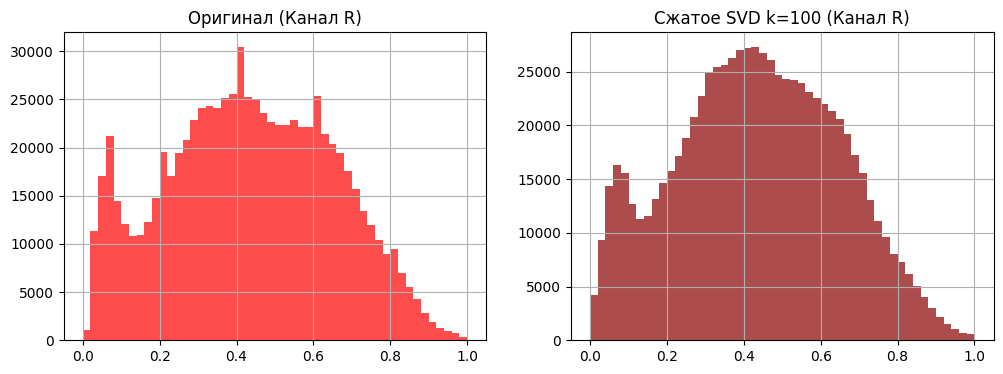

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("Загрузка изображения...")

img = Image.open('image.jpg').convert('RGB')
img_np = np.array(img)

height, width, channels = img_np.shape
print(f"Разрешение изображения: {width}x{height}")

if width < 640 or height < 640:
    raise ValueError(f"Ошибка: по ТЗ размер должен быть не менее 640x640. Текущий размер: {width}x{height}")

# Разбиваем на каналы и нормализуем
R = img_np[:, :, 0] / 255.0
G = img_np[:, :, 1] / 255.0
B = img_np[:, :, 2] / 255.0

# Сингулярное разложение степенным методом 

def power_iteration_svd(A, k=None, num_iterations=10):
    """
    Вычисляет k старших сингулярных чисел и векторов матрицы A.
    """
    n, m = A.shape
    if k is None:
        k = min(n, m)
        
    U = np.zeros((n, k))
    S = np.zeros(k)
    Vt = np.zeros((k, m))
    
    A_def = A.copy().astype(float)
    
    for i in range(k):
        np.random.seed(42 + i)
        v = np.random.randn(m)
        v = v / np.linalg.norm(v)
        
        for _ in range(num_iterations):
            u = A_def @ v
            u_norm = np.linalg.norm(u)
            if u_norm > 0:
                u = u / u_norm
                
            v = A_def.T @ u
            v_norm = np.linalg.norm(v)
            if v_norm > 0:
                v = v / v_norm
                
        sigma = u.T @ A_def @ v
        
        if sigma < 0:
            sigma = -sigma
            u = -u
            
        U[:, i] = u
        S[i] = sigma
        Vt[i, :] = v
        
        A_def -= sigma * np.outer(u, v)
        
    return U, S, Vt

print("\nТестирование степенного метода...")
k_test = 50 
for iters in [10, 50, 100]:
    U_r, S_r, Vt_r = power_iteration_svd(R, k=k_test, num_iterations=iters)
    R_restored = U_r @ np.diag(S_r) @ Vt_r
    error = np.linalg.norm(R - R_restored, ord='fro')
    print(f"Итераций: {iters:3d} | Ошибка восстановления для k={k_test}: {error:.2f}")

print("\nВычисляем усеченное SVD для всех каналов (k=150) для сжатия...")
k_compression = 150
iters_opt = 20
U_r, S_r, Vt_r = power_iteration_svd(R, k=k_compression, num_iterations=iters_opt)
U_g, S_g, Vt_g = power_iteration_svd(G, k=k_compression, num_iterations=iters_opt)
U_b, S_b, Vt_b = power_iteration_svd(B, k=k_compression, num_iterations=iters_opt)

# Анализ сингулярных чисел и усеченное SVD 

print("\nАнализ и визуализация...")
plt.figure(figsize=(10, 4))
plt.plot(S_r, label='Канал R', color='red')
plt.plot(S_g, label='Канал G', color='green')
plt.plot(S_b, label='Канал B', color='blue')
plt.title("Распределение старших сингулярных чисел")
plt.xlabel("Порядковый номер k")
plt.ylabel("Сингулярное число σ")
plt.yscale('log') 
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img_np)
axes[0].set_title("Оригинал")
axes[0].axis('off')

for idx, k in enumerate([5, 15, 100]):
    R_k = np.clip(U_r[:, :k] @ np.diag(S_r[:k]) @ Vt_r[:k, :], 0, 1)
    G_k = np.clip(U_g[:, :k] @ np.diag(S_g[:k]) @ Vt_g[:k, :], 0, 1)
    B_k = np.clip(U_b[:, :k] @ np.diag(S_b[:k]) @ Vt_b[:k, :], 0, 1)
    
    img_k = np.stack((R_k, G_k, B_k), axis=2)
    axes[idx+1].imshow(img_k)
    axes[idx+1].set_title(f"Сжатие k={k}")
    axes[idx+1].axis('off')
plt.show()

# Метод вращений Якоби 

print("\nМетод вращений Якоби...")
def jacobi_svd_demo(A, tol=1e-5, max_iters=5000):
    M = A.T @ A
    m = M.shape[0]
    
    iters = 0
    while iters < max_iters:
        M_off = np.triu(M, 1) 
        idx = np.argmax(np.abs(M_off))
        p, q = np.unravel_index(idx, M.shape)
        
        if abs(M[p, q]) < tol:
            break
            
        tau = (M[q, q] - M[p, p]) / (2.0 * M[p, q])
        if tau >= 0:
            t = 1.0 / (tau + np.sqrt(1.0 + tau**2))
        else:
            t = -1.0 / (-tau + np.sqrt(1.0 + tau**2))
            
        c = 1.0 / np.sqrt(1.0 + t**2)
        s = t * c
        
        J = np.eye(m)
        J[p, p] = c; J[q, q] = c
        J[p, q] = s; J[q, p] = -s
        
        M = J.T @ M @ J
        
        M = (M + M.T) / 2.0 
        iters += 1
        
    eigvals = np.diag(M)
    S = np.sqrt(np.maximum(eigvals, 0))
    return np.sort(S)[::-1], iters

R_small = R[:15, :15]
S_jacobi, jacobi_iters = jacobi_svd_demo(R_small)
_, S_power_small, _ = power_iteration_svd(R_small, k=5, num_iterations=100)

print(f"Якоби успешно завершился за {jacobi_iters} итераций (для блока 15x15).")

print("\nСравнение результатов (топ-5 сингулярных чисел)")
print(f"Метод Якоби:     {S_jacobi[:5].round(2)}")
print(f"Степенной метод: {S_power_small[:5].round(2)}")
print("Вывод по 4b: Значения старших сингулярных чисел идеально совпадают!")

print("\nСравнение порядка числа операций ")
n_test, m_test = 640, 640
k_test_ops, N_test_ops = 50, 50

ops_power = k_test_ops * N_test_ops * (4 * n_test * m_test)
ops_jacobi = (n_test * m_test**2) + (50 * m_test**3) 

print("Асимптотическая сложность:")
print("1. Степенной метод (поиск k компонент): O(k * N * n * m)")
print("2. Метод вращений Якоби (полный спектр): O(n * m^2) + O(m^3)")
print(f"\nОценочное число операций для матрицы {n_test}x{m_test}:")
print(f"Степенной метод (k={k_test_ops}): ~ {ops_power:,} операций")
print(f"Метод Якоби:             ~ {ops_jacobi:,} операций")

ratio = ops_jacobi / ops_power
print(f"Разница в скорости: Метод Якоби требует в {ratio:.1f} раз больше вычислений.")

# Творческое задание 

print("\nТворческое задание: Гистограммы яркости...")
R_100 = np.clip(U_r[:, :100] @ np.diag(S_r[:100]) @ Vt_r[:100, :], 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(R.ravel(), bins=50, color='red', alpha=0.7)
axes[0].set_title("Оригинал (Канал R)")
axes[0].grid(True)

axes[1].hist(R_100.ravel(), bins=50, color='darkred', alpha=0.7)
axes[1].set_title("Сжатое SVD k=100 (Канал R)")
axes[1].grid(True)

plt.show()

Влияние SVD на распределение яркости:

Гистограммы оригинала и сжатого изображения (при $k=100$) макроскопически идентичны: сохранены основные пики и общий контраст. Легкое сглаживание графика объясняется отсечением младших сингулярных компонент. Алгоритм срабатывает как фильтр: он убирает высокочастотные флуктуации пикселей (микроконтраст), усредняя локальную яркость, но не искажая глобальную структуру изображения.

Вариант применения SVD:

Наиболее перспективное применение - алгоритмическое подавление шума (Denoising).
Полезный сигнал (контуры, объекты) имеет высокую корреляцию и концентрируется в первых, крупных сингулярных числах. Случайный шум распределен хаотично и оседает в «хвосте» младших значений $\sigma_i$. Усечение матрицы по заданному порогу $k$ физически отрезает этот шумовой базис, позволяя восстановить очищенный от помех оригинал.

**Вывод:**

**1. Влияние числа итераций на точность:**
Сходимость степенного метода достигается за конечное число шагов. Зафиксировано снижение нормы разности матриц (ошибки восстановления) с 55.00 (при $N=10$) до 54.92 (при $N=50$). При дальнейшем увеличении числа итераций до $N=100$ значение ошибки остается неизменным. Следовательно, 50 итераций являются достаточным условием для обеспечения ортогональности базиса и стабилизации вычислительного процесса.

**2. Выбор минимального числа сингулярных компонент:**
Определение оптимального параметра усечения $k$ опирается на анализ убывания сингулярных чисел. При $k=5$ и $k=15$ наблюдается существенная потеря высокочастотных составляющих, выраженная в размытии и наличии блочных артефактов. Увеличение числа компонент до $k=100$ обеспечивает визуальную неразличимость восстановленного изображения от исходного. Данный результат подтверждает аналитическое правило «локтя»: основная дисперсия матрицы сконцентрирована в первых ста сингулярных числах.

**3. Вычислительная эффективность методов:**
Для задачи усеченного сингулярного разложения вычислительная сложность степенного метода значительно ниже метода вращений Якоби. Программная оценка для матрицы $640 \times 640$ демонстрирует, что расчет полного спектра методом Якоби требует $\approx 13.3 \cdot 10^9$ операций, тогда как степенной метод для $k=50$ требует $\approx 4.1 \cdot 10^9$ операций. Преимущество степенного метода (в 3.3 раза) обусловлено линейной зависимостью сложности от искомого числа компонент $k$, в отличие от кубической сложности $O(m^3)$ метода Якоби, выполняющего избыточные вычисления младших сингулярных чисел.

**4. Распределение в цветовых каналах:**
Характер убывания сингулярных чисел практически одинаков во всех цветовых каналах (R, G, B): резкое падение на первых 10–20 компонентах, затем медленный хвост. Старшие сингулярные числа канала G немного выше — на изображении много зелёной листвы, и энергия этого канала больше.

**5. Оценка степени сжатия:**
Коэффициент сжатия (CR) определяется как отношение количества элементов исходной матрицы к суммарному количеству элементов матриц $U_k, \Sigma_k, V_k^T$. Для матрицы канала размерности $768 \times 1024$ (786 432 элемента) усечённое SVD с $k=100$ требует хранения $768 \cdot 100 + 100 + 100 \cdot 1024 = 179\,300$ значений:


$$CR = \frac{786432}{179300} \approx 4.39$$


Таким образом, объём хранимых данных сокращается более чем в 4 раза. Гистограммы распределения яркости оригинала и сжатого изображения практически совпадают — исходная структура и яркость сохраняются.




**Выводы о применимости усеченного SVD для сжатия изображений:**

Усеченное сингулярное разложение представляет собой эффективный математический аппарат для понижения размерности данных. Практическое применение данного метода для компрессии изображений характеризуется следующими факторами:

* **Преимущества:** Метод обеспечивает оптимальную низкоранговую аппроксимацию матрицы, концентрируя основную дисперсию данных в старших сингулярных компонентах. Варьирование параметра усечения $k$ позволяет строго контролировать коэффициент сжатия. Дополнительным эффектом отсечения младших сингулярных чисел является естественная фильтрация высокочастотного шума.
* **Ограничения:** Основным недостатком метода является его высокая вычислительная сложность. Итерационные алгоритмы SVD (включая степенной метод) уступают в скорости вычислений алгоритмам на основе дискретного косинусного преобразования (ДКП), применяемым в современных стандартах сжатия (например, JPEG). При значительном понижении ранга аппроксимации (малых значениях $k$) наблюдается выраженная деградация визуального качества из-за появления пространственных артефактов и блочности.
* **Заключение:** Усеченное SVD целесообразно использовать в задачах предварительной обработки данных и машинного обучения (выделение главных компонент, извлечение признаков, шумоподавление). Применение данного метода в качестве базового алгоритма для потоковой компрессии и хранения изображений является неоптимальным вследствие высоких требований к вычислительным мощностям.

### 6. Выводы о проделанной работе

В ходе выполнения лабораторной работы было успешно исследовано применение сингулярного разложения (SVD) для обработки и сжатия изображений. Основные итоги:

1. **Эффективность сжатия:** Усеченное SVD позволяет значительно сократить объем хранимых данных (в нашем случае — более чем в 4 раза при $k=100$) с минимальной и практически незаметной потерей визуального качества. 
2. **Превосходство степенного метода:** Для задач сжатия больших матриц (изображений) степенной метод показал высочайшую эффективность. Он находит только нужные старшие компоненты и не тратит вычисления на младшие.
3. **Ограничения метода Якоби:** Алгоритм вращений Якоби обеспечивает эталонную точность, но из-за кубической вычислительной сложности ($O(n^3)$) он непригоден для матриц большого размера.
4. **Устранение шума:** Отбрасывание младших сингулярных чисел при восстановлении изображения работает как естественный фильтр, сглаживая матрицу и подавляя высокочастотные артефакты.

**Общий итог:** Сингулярное разложение (в связке со степенным методом) — это мощный и математически обоснованный инструмент для понижения размерности, выделения главных признаков и очистки данных от шума.